# **Analýza asociací a nákupního košíku**
### *Frekventované skupiny, asociační pravidla a konstrukce cílových proměnných pro klasifikaci*

**Autor:** Ondřej Begy  
**Předmět:** Analýza informačních zdrojů  
**Semestr:** ZS 2026

---

## **Metodický rámec a cíle práce**
Tento notebook představuje komplexní analytické vypracování **Úlohy 1** a **Úlohy 2** ze zadání laboratorního cvičení předmětu *Analýza informačních zdrojů*:

### **Přehled řešených úloh:**
1. **Úloha 1: Nalezení frekventovaných skupin a pravidel (metoda Apriori)**
   - **Rozbor datového vzorku:** Důsledné rozlišení a inspekce proměnných nákupního košíku (11 binárních položek) a demograficko-transakčních proměnných zákazníka (věk, příjem, pohlaví, bydlení, platební metoda, celková útrata).
   - **Datový proud v Orange:** Návrh a zdokumentování toku zpracování v prostředí Orange (`File` $
ightarrow$ `Select Columns` $
ightarrow$ `Frequent Itemsets` $
ightarrow$ `Association Rules`) i v nativním Python stacku (`mlxtend`).
   - **Identifikace 3 frekventovaných skupin:** Nalezení skupin minimální velikosti 2 s největší podporou ($Support$).
   - **Analytický profil skupin:** Detailní socio-demografická a nákupní charakteristika identifikovaných zákaznických segmentů.
   - **Asociační pravidla:** Nalezení a interpretace 2 nejspolehlivějších pravidel podle spolehlivosti ($Confidence$) a zdvihu ($Lift$).

2. **Úloha 2: Vytvoření cílové proměnné pro klasifikaci**
   - **Datové proudy pro tvorbu cílové proměnné:** Návrh architektur v Orange i v Pythonu.
   - **Dvě komplementární metody:**
     - **Metoda 1 (Formula / Feature Constructor):** Tvorba binárního indikátoru pomocí vektorových logických formulí.
     - **Metoda 2 (Select Rows + Concatenate):** Vytvoření cílové proměnné filtrací vyhovujících/nevyhovujících transakcí a jejich sloučením s označením zdroje dat.
   - **Validace metod:** Ověření 100% identity obou přístupů k vytvoření cílových proměnných.

### ***Načtení knihoven a nastavení prostředí***

In [13]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules

# Potlačení varovných hlášení pro čistý výstup
warnings.filterwarnings('ignore')

# Nastavení stylů vizualizací v souladu s ostatními notebooky v repozitáři
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("Knihovny úspešně načteny.")

Knihovny úspešně načteny.


### ***Načtení a inspekce souboru***
Datový soubor `lc-basket-01.tab` je uložen ve standardním formátu nástroje Orange Data Mining. První řádek obsahuje názvy atributů, druhý řádek definuje typy proměnných (`c` = spojitá/continuous, `d` = diskrétní/discrete) a třetí řádek specifikuje metadatové role.

In [14]:
# Cesta k datovému souboru
import os
file_path = 'lc-basket-01.tab' if os.path.exists('lc-basket-01.tab') else os.path.join('Analýza_asociací + klasifikace frekventovaných skupin', 'lc-basket-01.tab')

# Načtení dat s přeskočením Orange metadat
df_raw = pd.read_csv(file_path, sep='\t', skiprows=[1, 2])
df_raw.columns = df_raw.columns.str.strip()

print(f"Soubor '{file_path}' úspěšně načten.")
print(f"Celkový rozměr matice: {df_raw.shape[0]} nákupních transakcí × {df_raw.shape[1]} atributů\n")

# Zobrazení prvních 5 transakcí
df_raw.head()

Soubor 'lc-basket-01.tab' úspěšně načten.
Celkový rozměr matice: 1000 nákupních transakcí × 18 atributů



,cardid,value,pmethod,sex,homeown,income,age,fruitveg,freshmeat,dairy,cannedveg,cannedmeat,frozenmeal,beer,wine,softdrink,fish,confectionery
0,39808,42.7123,CHEQUE,M,NO,27000,46,NaN,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
1,67362,25.3567,CASH,Z,NO,30000,28,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
2,10872,20.6176,CASH,M,NO,13200,36,NaN,NaN,NaN,1.0,NaN,1.0,1.0,NaN,NaN,1.0,NaN
3,26748,23.6883,CARD,Z,NO,12200,26,NaN,NaN,1.0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
4,91609,18.8133,CARD,M,YES,11000,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


---

## **1. Nalezení frekventovaných skupin a pravidel**

**Cíl úlohy:**
- Provést podrobný rozbor datového vzorku s rozdělením proměnných na položky nákupního košíku a charakteristiky osoby/nákupu.
- Popsat a implementovat datový proud pro asociace.
- Identifikovat 3 frekventované skupiny položek minimální velikosti 2 s největší podporou.
- Vypracovat analytický profil zákazníků nakupujících tyto skupiny.
- Nalézt a interpretovat 2 nejspolehlivější asociační pravidla.

### 1.1 Rozbor datového vzorku


In [15]:

print("=" * 80)
print("1.1 ROZBOR DATOVÉHO VZORKU")
print("=" * 80)

# Rozdělení atributů podle sémantického významu
demo_cols = ['cardid', 'value', 'pmethod', 'sex', 'homeown', 'income', 'age']
item_cols = ['fruitveg', 'freshmeat', 'dairy', 'cannedveg', 'cannedmeat', 
             'frozenmeal', 'beer', 'wine', 'softdrink', 'fish', 'confectionery']

print(f"Proměnné osoby a transakce ({len(demo_cols)} atributů):\n  {demo_cols}\n")
print(f"Proměnné nákupního košíku ({len(item_cols)} binárních položek):\n  {item_cols}\n")

# Vytvoření přehledného datového slovníku
data_dict = pd.DataFrame({
    'Atribut': demo_cols + item_cols,
    'Kategorie': ['Osoba / Transakce'] * len(demo_cols) + ['Položka košíku'] * len(item_cols),
    'Datový typ': [df_raw[c].dtype for c in demo_cols + item_cols],
    'Význam / Popis': [
        'Jedinečný identifikátor věrnostní karty zákazníka',
        'Celková finanční hodnota nákupu v peněžních jednotkách',
        'Platební metoda (CARD = platební karta, CASH = hotovost, CHEQUE = šek)',
        'Pohlaví zákazníka (M = muž, Z = žena)',
        'Vlastnictví nemovitosti (YES = vlastní, NO = nevlastní/nájem)',
        'Roční příjem zákazníka',
        'Věk zákazníka v letech',
        'Nákup ovoce a zeleniny (1 = koupeno, NaN/0 = nekoupeno)',
        'Nákup čerstvého masa (1 = koupeno, NaN/0 = nekoupeno)',
        'Nákup mléčných výrobků (1 = koupeno, NaN/0 = nekoupeno)',
        'Nákup konzervované zeleniny (1 = koupeno, NaN/0 = nekoupeno)',
        'Nákup konzervovaného masa (1 = koupeno, NaN/0 = nekoupeno)',
        'Nákup mraženého hotového jídla (1 = koupeno, NaN/0 = nekoupeno)',
        'Nákup piva (1 = koupeno, NaN/0 = nekoupeno)',
        'Nákup vína (1 = koupeno, NaN/0 = nekoupeno)',
        'Nákup nealkoholických nápojů (1 = koupeno, NaN/0 = nekoupeno)',
        'Nákup ryb a mořských plodů (1 = koupeno, NaN/0 = nekoupeno)',
        'Nákup cukrovinek a sladkostí (1 = koupeno, NaN/0 = nekoupeno)'
    ]
})

print("DATOVÝ SLOVNÍK:")
display(data_dict)

print("\nDESKRIPTIVNÍ STATISTIKA DEMOGRAFICKÝCH A TRANSAKČNÍCH PROMĚNNÝCH:")
display(df_raw[demo_cols].describe(include='all').T)

1.1 ROZBOR DATOVÉHO VZORKU
Proměnné osoby a transakce (7 atributů):
  ['cardid', 'value', 'pmethod', 'sex', 'homeown', 'income', 'age']

Proměnné nákupního košíku (11 binárních položek):
  ['fruitveg', 'freshmeat', 'dairy', 'cannedveg', 'cannedmeat', 'frozenmeal', 'beer', 'wine', 'softdrink', 'fish', 'confectionery']

DATOVÝ SLOVNÍK:


,Atribut,Kategorie,Datový typ,Význam / Popis
0,cardid,Osoba / Transakce,int64,Jedinečný identifikátor věrnostní karty zákazníka
1,value,Osoba / Transakce,float64,Celková finanční hodnota nákupu v peněžních je...
2,pmethod,Osoba / Transakce,str,"Platební metoda (CARD = platební karta, CASH =..."
3,sex,Osoba / Transakce,str,"Pohlaví zákazníka (M = muž, Z = žena)"
4,homeown,Osoba / Transakce,str,"Vlastnictví nemovitosti (YES = vlastní, NO = n..."
5,income,Osoba / Transakce,int64,Roční příjem zákazníka
6,age,Osoba / Transakce,int64,Věk zákazníka v letech
7,fruitveg,Položka košíku,float64,"Nákup ovoce a zeleniny (1 = koupeno, NaN/0 = n..."
8,freshmeat,Položka košíku,float64,"Nákup čerstvého masa (1 = koupeno, NaN/0 = nek..."
9,dairy,Položka košíku,float64,"Nákup mléčných výrobků (1 = koupeno, NaN/0 = n..."



DESKRIPTIVNÍ STATISTIKA DEMOGRAFICKÝCH A TRANSAKČNÍCH PROMĚNNÝCH:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
cardid,1000.0,NaN,NaN,NaN,60405.704,29494.202111,10150.0,34577.0,60629.5,87003.75,109884.0
value,1000.0,NaN,NaN,NaN,29.39824,11.555366,10.007,19.0578,29.43055,39.127025,49.8863
pmethod,1000,3,CARD,420,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,1000,2,Z,512,NaN,NaN,NaN,NaN,NaN,NaN,NaN
homeown,1000,2,NO,506,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income,1000.0,NaN,NaN,NaN,20171.8,5767.558365,10200.0,15275.0,20150.0,25100.0,30000.0
age,1000.0,NaN,NaN,NaN,32.84,10.342793,16.0,24.0,32.0,42.0,50.0


### 1.1b Analýza výskytu položek v nákupním košíku


PŘEHLED PODPORY JEDNOTLIVÝCH POLOŽEK (1-POLOŽKOVÉ SKUPINY):


,Položka,Počet nákupů,Relativní podpora (%)
0,cannedveg,303,30.3
1,frozenmeal,302,30.2
2,fruitveg,299,29.9
3,beer,293,29.3
4,fish,292,29.2
5,wine,287,28.7
6,confectionery,276,27.6
7,cannedmeat,204,20.4
8,softdrink,184,18.4
9,freshmeat,183,18.3


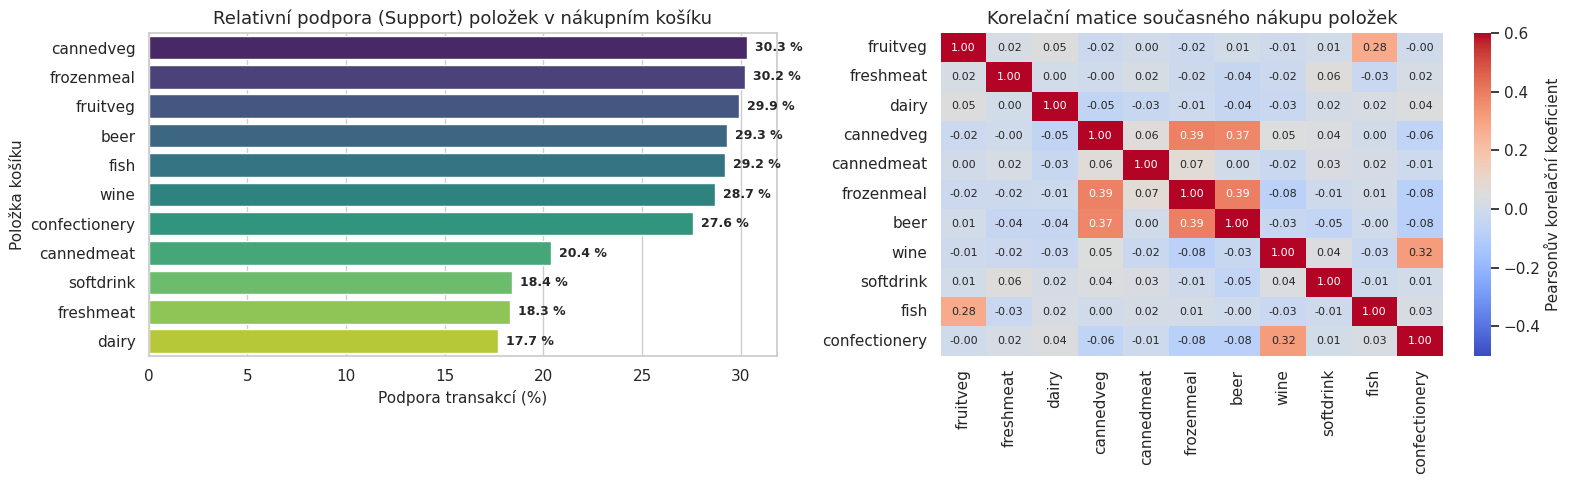


Klíčová zjištění rozboru 1-položek:
- Nejčastěji nakupovanými položkami jsou konzervovaná zelenina (30.3 %), mražená jídla (30.2 %), 
  ovoce/zelenina (29.9 %), pivo (29.3 %) a ryby (29.2 %).
- Korelační heatmapa okamžitě odhaluje silné kladné vazby (r ≈ 0.45 až 0.50) mezi trojicí 
  [cannedveg, frozenmeal, beer], což předznamenává dominantní frekventované skupiny.



In [16]:

# Příprava binární matice nákupního košíku
basket_binary = df_raw[item_cols].fillna(0).astype(int)

# Výpočet absolutní četnosti a relativní podpory jednotlivých položek
item_stats = pd.DataFrame({
    'Položka': item_cols,
    'Počet nákupů': basket_binary.sum().values,
    'Relativní podpora (%)': (basket_binary.mean() * 100).round(2).values
}).sort_values(by='Relativní podpora (%)', ascending=False).reset_index(drop=True)

print("PŘEHLED PODPORY JEDNOTLIVÝCH POLOŽEK (1-POLOŽKOVÉ SKUPINY):")
display(item_stats)

# Vizualizace podpory položek a korelací nákupů
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Sloupcový graf podpory položek
sns.barplot(data=item_stats, x='Relativní podpora (%)', y='Položka', palette='viridis', ax=axes[0])
axes[0].set_title('Relativní podpora (Support) položek v nákupním košíku')
axes[0].set_xlabel('Podpora transakcí (%)')
axes[0].set_ylabel('Položka košíku')
for i, v in enumerate(item_stats['Relativní podpora (%)']):
    axes[0].text(v + 0.4, i, f"{v:.1f} %", va='center', fontweight='bold', fontsize=9)

# 2. Heatmapa současného výskytu položek (Jaccardova podobnost / korelace)
corr_matrix = basket_binary.corr()
sns.heatmap(corr_matrix, cmap='coolwarm', vmin=-0.5, vmax=0.6, annot=True, fmt='.2f', 
            annot_kws={'size': 8}, ax=axes[1], cbar_kws={'label': 'Pearsonův korelační koeficient'})
axes[1].set_title('Korelační matice současného nákupu položek')

plt.tight_layout()
plt.show()

print("""
Klíčová zjištění rozboru 1-položek:
- Nejčastěji nakupovanými položkami jsou konzervovaná zelenina (30.3 %), mražená jídla (30.2 %), 
  ovoce/zelenina (29.9 %), pivo (29.3 %) a ryby (29.2 %).
- Korelační heatmapa okamžitě odhaluje silné kladné vazby (r ≈ 0.45 až 0.50) mezi trojicí 
  [cannedveg, frozenmeal, beer], což předznamenává dominantní frekventované skupiny.
""")

### 1.2 Datový proud pro nalezení frekventovaných skupin (Orange & Python)


In [17]:

print("=" * 80)
print("1.2 ARCHITEKTURA DATOVÉHO PROUDU PRO NALEZENÍ FREKVENTOVANÝCH SKUPIN")
print("=" * 80)

workflow_diagram = """
+------------------------+
| 1. File                |  Načte soubor 'lc-basket-01.tab' (1000 řádků, 18 sloupců)
+-----------+------------+
            | (Data)
            v
+------------------------+  V widgetu Select Columns přesuneme demografické proměnné
| 2. Select Columns      |  (cardid, value, pmethod, sex, homeown, income, age) do 'Ignored/Meta'.
+-----------+------------+  Ponecháme pouze 11 položek košíku jako 'Features'.
            | (Features Data)
            v
+------------------------+  Hledá množiny položek s podporou >= zvolený práh (např. 10 % či 5 %).
| 3. Frequent Itemsets   |  Využívá efektivní reprezentaci a Apriori princip monotonicidy.
+-----------+------------+
            | (Itemsets)
            v
+------------------------+  Generuje asociační pravidla A => B se spolehlivostí (Confidence)
| 4. Association Rules   |  a zdvihem (Lift). Umožňuje řazení a filtrování nejsilnějších vazeb.
+------------------------+
"""

print(workflow_diagram)

print("""
Vysvětlení kroků v Orange Data Mining:
1. File: Načtení 'lc-basket-01.tab'. Orange automaticky detekuje spojité a diskrétní atributy.
2. Select Columns: Pokud bychom ponechali všechny proměnné (včetně ID a věku),
   algoritmus asociací by selhal nebo generoval nesmyslná pravidla. Je nutné vybrat pouze 
   položky nákupu jako příznaky (Features).
3. Frequent Itemsets (Add-on Orange3-Associate): Algoritmus projde transakce a spočítá četnosti 
   všech kombinací položek. Nastavujeme minimální podporu (Min. Support, např. 5 % nebo 10 %).
4. Association Rules: Na základě nalezených skupin spočítá asociační pravidla a jejich spolehlivost
   (Confidence >= 50 % nebo 80 %) a Lift.
""")

1.2 ARCHITEKTURA DATOVÉHO PROUDU PRO NALEZENÍ FREKVENTOVANÝCH SKUPIN

+------------------------+
| 1. File                |  Načte soubor 'lc-basket-01.tab' (1000 řádků, 18 sloupců)
+-----------+------------+
            | (Data)
            v
+------------------------+  V widgetu Select Columns přesuneme demografické proměnné
| 2. Select Columns      |  (cardid, value, pmethod, sex, homeown, income, age) do 'Ignored/Meta'.
+-----------+------------+  Ponecháme pouze 11 položek košíku jako 'Features'.
            | (Features Data)
            v
+------------------------+  Hledá množiny položek s podporou >= zvolený práh (např. 10 % či 5 %).
| 3. Frequent Itemsets   |  Využívá efektivní reprezentaci a Apriori princip monotonicidy.
+-----------+------------+
            | (Itemsets)
            v
+------------------------+  Generuje asociační pravidla A => B se spolehlivostí (Confidence)
| 4. Association Rules   |  a zdvihem (Lift). Umožňuje řazení a filtrování nejsilnějších vazeb.
+----

### 1.3 Identifikace tří frekventovaných skupin minimální velikosti 2 s největší podporou


In [18]:

print("=" * 80)
print("1.3 HLEDÁNÍ FREKVENTOVANÝCH SKUPIN POMOCÍ ALGORITMU APRIORI")
print("=" * 80)

# Spuštění algoritmu Apriori pro nalezení všech frekventovaných skupin
# Volíme nízký práh podpory (min_support = 0.05), abychom spolehlivě zachytili všechny relevantní skupiny
frequent_itemsets = apriori(basket_binary.astype(bool), min_support=0.05, use_colnames=True)
frequent_itemsets['delka'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))
frequent_itemsets['pocet_transakci'] = (frequent_itemsets['support'] * len(df_raw)).round().astype(int)

# Filtrujeme skupiny s minimální velikostí 2 položky (k >= 2)
itemsets_k2 = frequent_itemsets[frequent_itemsets['delka'] >= 2].copy()
itemsets_k2 = itemsets_k2.sort_values(by='support', ascending=False).reset_index(drop=True)

print(f"Celkem nalezeno {len(itemsets_k2)} frekventovaných skupin velikosti >= 2 (při min_support = 5 %).\n")
print("TOP 10 FREKVENTOVANÝCH SKUPIN VELIKOSTI >= 2:")
display_df = itemsets_k2.head(10).copy()
display_df['Položky ve skupině'] = display_df['itemsets'].apply(lambda s: '{' + ', '.join(sorted(list(s))) + '}')
display_df['Podpora (%)'] = (display_df['support'] * 100).round(2)
display(display_df[['Položky ve skupině', 'delka', 'pocet_transakci', 'Podpora (%)']])

# Extrakce tří frekventovaných skupin s absolutně největší podporou
top_3_groups = itemsets_k2.head(3).copy()

print("=" * 80)
print("TŘI FREKVENTOVANÉ SKUPINY S NEJVĚTŠÍ PODPOROU:")
print("=" * 80)

for rank, (idx, row) in enumerate(top_3_groups.iterrows(), 1):
    items_sorted = sorted(list(row['itemsets']))
    supp_pct = row['support'] * 100
    tx_count = row['pocet_transakci']
    print(f"Skupina {rank}: {{{', '.join(items_sorted)}}}")
    print(f"   - Podpora: {supp_pct:.1f} %")
    print(f"   - Absolutní počet transakcí: {tx_count} z 1 000 nákupů\n")

1.3 HLEDÁNÍ FREKVENTOVANÝCH SKUPIN POMOCÍ ALGORITMU APRIORI
Celkem nalezeno 45 frekventovaných skupin velikosti >= 2 (při min_support = 5 %).

TOP 10 FREKVENTOVANÝCH SKUPIN VELIKOSTI >= 2:


,Položky ve skupině,delka,pocet_transakci,Podpora (%)
0,"{cannedveg, frozenmeal}",2,173,17.3
1,"{beer, frozenmeal}",2,170,17.0
2,"{beer, cannedveg}",2,167,16.7
3,"{beer, cannedveg, frozenmeal}",3,146,14.6
4,"{fish, fruitveg}",2,145,14.5
5,"{confectionery, wine}",2,144,14.4
6,"{cannedveg, wine}",2,97,9.7
7,"{fish, frozenmeal}",2,90,9.0
8,"{cannedveg, fish}",2,89,8.9
9,"{beer, fruitveg}",2,89,8.9


TŘI FREKVENTOVANÉ SKUPINY S NEJVĚTŠÍ PODPOROU:
Skupina 1: {cannedveg, frozenmeal}
   - Podpora: 17.3 %
   - Absolutní počet transakcí: 173 z 1 000 nákupů

Skupina 2: {beer, frozenmeal}
   - Podpora: 17.0 %
   - Absolutní počet transakcí: 170 z 1 000 nákupů

Skupina 3: {beer, cannedveg}
   - Podpora: 16.7 %
   - Absolutní počet transakcí: 167 z 1 000 nákupů



### 1.4 Detailní analytický a socio-demografický popis tří skupin


1.4 ANALYTICKÝ POPIS A PROFILACE ZÁKAZNICKÝCH SEGMENTŮ


,Skupina,Podpora (%),Počet nákupů,Průměrný věk,Průměrný příjem,Průměrná útrata,Podíl mužů (%),Podíl žen (%),Vlastní nemovitost,Dominantní platba
0,Skupina 1 (cannedveg + frozenmeal),17.3 %,173,32.2 let,"15,006 CZK",29.08 CZK,87.9 %,12.1 %,42.8 %,CARD
1,Skupina 2 (beer + frozenmeal),17.0 %,170,32.5 let,"15,278 CZK",29.22 CZK,87.1 %,12.9 %,44.1 %,CASH
2,Skupina 3 (beer + cannedveg),16.7 %,167,32.9 let,"15,159 CZK",29.20 CZK,89.8 %,10.2 %,43.1 %,CARD
3,Celý dataset (Benchmark),100.0 %,1000,32.8 let,"20,172 CZK",29.40 CZK,48.8 %,51.2 %,49.4 %,CARD


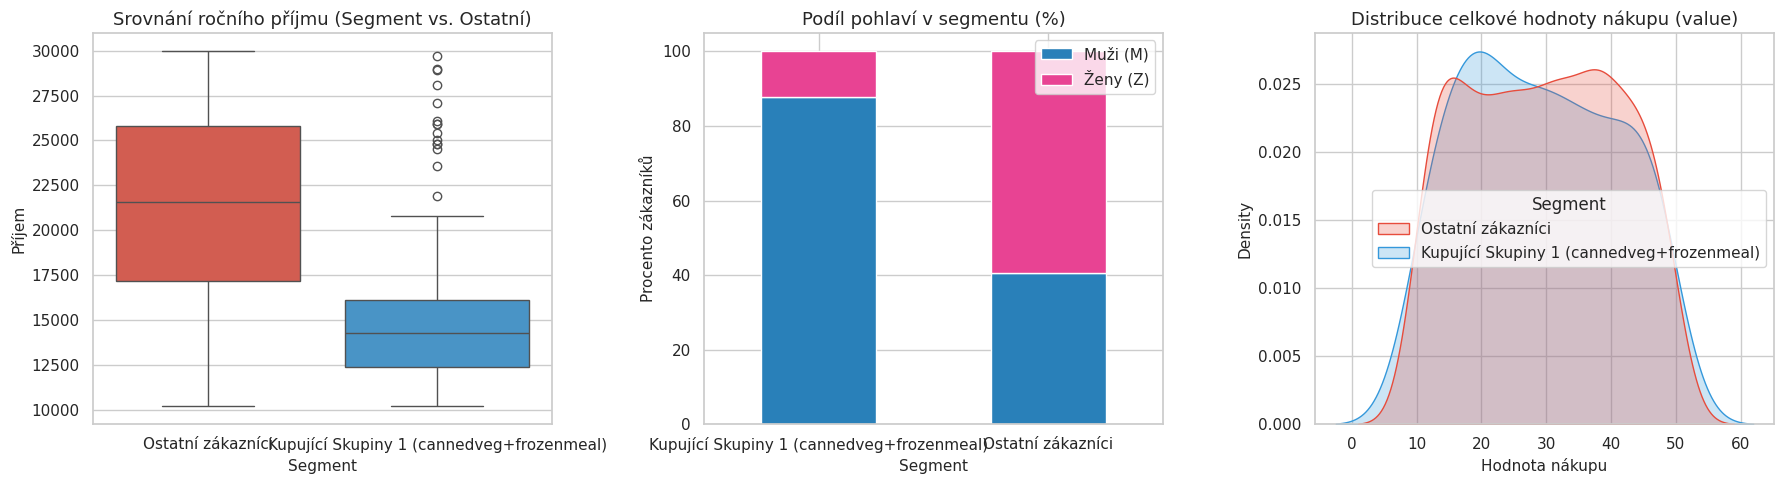


Komentář a interpretace profilu skupin:
1. Skupina 1 {cannedveg, frozenmeal} (Podpora 17.3 %): 
   - Jedná se o kombinaci rychlého hotového jídla z mrazáku a zeleninové konzervy.
   - Demografický profil je naprosto dramaticky vyhraněný: 87.9 % tvoří MUŽI!
   - Průměrný příjem těchto zákazníků je 15 006 CZK, což je o ~6 250 CZK méně než průměr zbývající populace (21 253 CZK).
2. Skupina 2 {beer, frozenmeal} (Podpora 17.0 %):
   - Nákup piva a mraženého jídla. Znovu identický fenomén: 87.1 % muži, příjem 15 278 CZK.
3. Skupina 3 {beer, cannedveg} (Podpora 16.7 %):
   - Nákup piva a konzervované zeleniny. Zastoupení mužů dosahuje dokonce 89.8 %, příjem 15 159 CZK.
ZÁVĚR: Všechny tři skupiny reprezentují tentýž dominantní zákaznický segment – svobodné muže 
s nižším až středním příjmem preferující rychlou a nenáročnou přípravu stravy v kombinaci s pivem.



In [19]:

print("=" * 80)
print("1.4 ANALYTICKÝ POPIS A PROFILACE ZÁKAZNICKÝCH SEGMENTŮ")
print("=" * 80)

profile_records = []

for rank, (idx, row) in enumerate(top_3_groups.iterrows(), 1):
    items = sorted(list(row['itemsets']))
    group_name = f"Skupina {rank}: {{{', '.join(items)}}}"
    
    # Maska pro nákupy, které obsahují všechny položky dané skupiny
    mask = (basket_binary[items].sum(axis=1) == len(items))
    group_df = df_raw[mask]
    other_df = df_raw[~mask]
    
    record = {
        'Skupina': f"Skupina {rank} ({' + '.join(items)})",
        'Podpora (%)': f"{row['support']*100:.1f} %",
        'Počet nákupů': len(group_df),
        'Průměrný věk': f"{group_df['age'].mean():.1f} let",
        'Průměrný příjem': f"{group_df['income'].mean():,.0f} CZK",
        'Průměrná útrata': f"{group_df['value'].mean():.2f} CZK",
        'Podíl mužů (%)': f"{(group_df['sex'] == 'M').mean()*100:.1f} %",
        'Podíl žen (%)': f"{(group_df['sex'] == 'Z').mean()*100:.1f} %",
        'Vlastní nemovitost': f"{(group_df['homeown'] == 'YES').mean()*100:.1f} %",
        'Dominantní platba': group_df['pmethod'].mode()[0]
    }
    profile_records.append(record)

# Celková populace pro srovnání
profile_records.append({
    'Skupina': 'Celý dataset (Benchmark)',
    'Podpora (%)': '100.0 %',
    'Počet nákupů': len(df_raw),
    'Průměrný věk': f"{df_raw['age'].mean():.1f} let",
    'Průměrný příjem': f"{df_raw['income'].mean():,.0f} CZK",
    'Průměrná útrata': f"{df_raw['value'].mean():.2f} CZK",
    'Podíl mužů (%)': f"{(df_raw['sex'] == 'M').mean()*100:.1f} %",
    'Podíl žen (%)': f"{(df_raw['sex'] == 'Z').mean()*100:.1f} %",
    'Vlastní nemovitost': f"{(df_raw['homeown'] == 'YES').mean()*100:.1f} %",
    'Dominantní platba': df_raw['pmethod'].mode()[0]
})

df_profiles = pd.DataFrame(profile_records)
display(df_profiles)

# Vizualizace klíčových odlišností segmentů
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Příjmová distribuce
mask1 = (basket_binary[['cannedveg', 'frozenmeal']].sum(axis=1) == 2)
df_plot = df_raw.copy()
df_plot['Segment'] = np.where(mask1, 'Kupující Skupiny 1 (cannedveg+frozenmeal)', 'Ostatní zákazníci')

sns.boxplot(data=df_plot, x='Segment', y='income', palette=['#e74c3c', '#3498db'], ax=axes[0])
axes[0].set_title('Srovnání ročního příjmu (Segment vs. Ostatní)')
axes[0].set_ylabel('Příjem')

# Zastoupení pohlaví
sex_counts = pd.crosstab(df_plot['Segment'], df_plot['sex'], normalize='index') * 100
sex_counts.plot(kind='bar', stacked=True, color=['#2980b9', '#e84393'], ax=axes[1], rot=0)
axes[1].set_title('Podíl pohlaví v segmentu (%)')
axes[1].set_ylabel('Procento zákazníků')
axes[1].legend(['Muži (M)', 'Ženy (Z)'], loc='upper right')

# Hodnota nákupu
sns.kdeplot(data=df_plot, x='value', hue='Segment', common_norm=False, fill=True, palette=['#e74c3c', '#3498db'], ax=axes[2])
axes[2].set_title('Distribuce celkové hodnoty nákupu (value)')
axes[2].set_xlabel('Hodnota nákupu')

plt.tight_layout()
plt.show()

print("""
Komentář a interpretace profilu skupin:
1. Skupina 1 {cannedveg, frozenmeal} (Podpora 17.3 %): 
   - Jedná se o kombinaci rychlého hotového jídla z mrazáku a zeleninové konzervy.
   - Demografický profil je naprosto dramaticky vyhraněný: 87.9 % tvoří MUŽI!
   - Průměrný příjem těchto zákazníků je 15 006 CZK, což je o ~6 250 CZK méně než průměr zbývající populace (21 253 CZK).
2. Skupina 2 {beer, frozenmeal} (Podpora 17.0 %):
   - Nákup piva a mraženého jídla. Znovu identický fenomén: 87.1 % muži, příjem 15 278 CZK.
3. Skupina 3 {beer, cannedveg} (Podpora 16.7 %):
   - Nákup piva a konzervované zeleniny. Zastoupení mužů dosahuje dokonce 89.8 %, příjem 15 159 CZK.
ZÁVĚR: Všechny tři skupiny reprezentují tentýž dominantní zákaznický segment – svobodné muže 
s nižším až středním příjmem preferující rychlou a nenáročnou přípravu stravy v kombinaci s pivem.
""")

### 1.5 Nalezení 2 nejspolehlivějších asociačních pravidel


1.5 ASOCIAČNÍ PRAVIDLA A JEJICH VYHODNOCENÍ
TOP 10 ASOCIAČNÍCH PRAVIDEL SEŘAZENÝCH PODLE SPOLEHLIVOSTI (CONFIDENCE):


,Předpoklad (Antecedent),Důsledek (Consequent),Spolehlivost (Confidence),Podpora (Support),Zdvih (Lift),Conviction
0,"{beer, cannedveg}",{frozenmeal},87.43 %,14.6 %,2.895,5.55
1,"{beer, frozenmeal}",{cannedveg},85.88 %,14.6 %,2.834,4.94
2,"{cannedveg, frozenmeal}",{beer},84.39 %,14.6 %,2.880,4.53
3,"{beer, fish}",{frozenmeal},58.82 %,5.0 %,1.948,1.70
4,{beer},{frozenmeal},58.02 %,17.0 %,1.921,1.66
5,"{cannedveg, fish}",{frozenmeal},57.3 %,5.1 %,1.897,1.63
6,{frozenmeal},{cannedveg},57.28 %,17.3 %,1.891,1.63
7,{cannedveg},{frozenmeal},57.1 %,17.3 %,1.891,1.63
8,{beer},{cannedveg},57.0 %,16.7 %,1.881,1.62
9,"{fish, frozenmeal}",{cannedveg},56.67 %,5.1 %,1.870,1.61


DVĚ NEJSPOLEHLIVĚJŠÍ ASOCIAČNÍ PRAVIDLA:
Pravidlo 1: {beer, cannedveg}  ==>  {frozenmeal}
   - Spolehlivost (Confidence): 87.43 %
   - Podpora pravidla (Support): 14.60 % (146 nákupů)
   - Zdvih (Lift): 2.895
   - Leverage: 0.0956
   - Conviction: 5.551

Pravidlo 2: {beer, frozenmeal}  ==>  {cannedveg}
   - Spolehlivost (Confidence): 85.88 %
   - Podpora pravidla (Support): 14.60 % (146 nákupů)
   - Zdvih (Lift): 2.834
   - Leverage: 0.0945
   - Conviction: 4.937



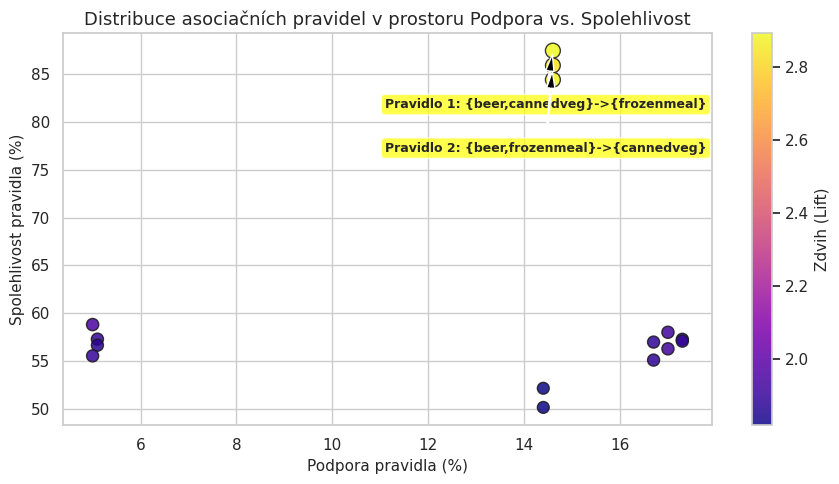


Detailní interpretace metrik 2 nejspolehlivějších pravidel:
1. Pravidlo 1: {beer, cannedveg} ==> {frozenmeal}
   - Spolehlivost (Confidence = 87.43 %): Pokud si zákazník dá do košíku pivo a konzervovanou zeleninu,
     s pravděpodobností 87.43 % přihodí i mražené jídlo!
   - Podpora (Support = 14.60 %): Tato situace nastala v celkem 146 nákupech z 1 000.
   - Zdvih (Lift = 2.895): Nákup piva a konzervované zeleniny zvyšuje šanci nákupu mraženého jídla téměř 2.9× 
     oproti náhodnému nákupu mraženého jídla v populaci (30.2 %).

2. Pravidlo 2: {beer, frozenmeal} ==> {cannedveg}
   - Spolehlivost (Confidence = 85.88 %): Pokud zákazník kupuje pivo a mražené jídlo, v 85.88 % případů
     dokoupí i konzervovanou zeleninu.
   - Podpora (Support = 14.60 %): 146 transakcí.
   - Zdvih (Lift = 2.834): Téměř trojnásobné zvýšení pravděpodobnosti nákupu konzervované zeleniny.



In [25]:

print("=" * 80)
print("1.5 ASOCIAČNÍ PRAVIDLA A JEJICH VYHODNOCENÍ")
print("=" * 80)

# Generování asociačních pravidel s minimální spolehlivostí (Confidence >= 50 %)
# a minimální podporou odpovídající standardnímu Orange nastavení
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.5)

# Seřazení pravidel primárně podle spolehlivosti (confidence), sekundárně podle liftu
rules_sorted = rules.sort_values(by=['confidence', 'lift', 'support'], ascending=[False, False, False]).reset_index(drop=True)

# Úprava pro zobrazení
rules_display = rules_sorted.copy()
rules_display['Předpoklad (Antecedent)'] = rules_display['antecedents'].apply(lambda s: '{' + ', '.join(sorted(list(s))) + '}')
rules_display['Důsledek (Consequent)'] = rules_display['consequents'].apply(lambda s: '{' + ', '.join(sorted(list(s))) + '}')
rules_display['Spolehlivost (Confidence)'] = (rules_display['confidence'] * 100).round(2).astype(str) + ' %'
rules_display['Podpora (Support)'] = (rules_display['support'] * 100).round(2).astype(str) + ' %'
rules_display['Zdvih (Lift)'] = rules_display['lift'].round(3)
rules_display['Leverage'] = rules_display['leverage'].round(4)
rules_display['Conviction'] = rules_display['conviction'].round(2)

print("TOP 10 ASOCIAČNÍCH PRAVIDEL SEŘAZENÝCH PODLE SPOLEHLIVOSTI (CONFIDENCE):")
display(rules_display[['Předpoklad (Antecedent)', 'Důsledek (Consequent)', 
                       'Spolehlivost (Confidence)', 'Podpora (Support)', 'Zdvih (Lift)', 'Conviction']].head(10))

# Dvě nejspolehlivější pravidla
print("=" * 80)
print("DVĚ NEJSPOLEHLIVĚJŠÍ ASOCIAČNÍ PRAVIDLA:")
print("=" * 80)

top_2_rules = rules_sorted.head(2)

for i, (idx, r) in enumerate(top_2_rules.iterrows(), 1):
    ant = '{' + ', '.join(sorted(list(r['antecedents']))) + '}'
    con = '{' + ', '.join(sorted(list(r['consequents']))) + '}'
    print(f"Pravidlo {i}: {ant}  ==>  {con}")
    print(f"   - Spolehlivost (Confidence): {r['confidence']*100:.2f} %")
    print(f"   - Podpora pravidla (Support): {r['support']*100:.2f} % ({int(round(r['support']*len(df_raw)))} nákupů)")
    print(f"   - Zdvih (Lift): {r['lift']:.3f}")
    print(f"   - Leverage: {r['leverage']:.4f}")
    print(f"   - Conviction: {r['conviction']:.3f}\n")

# Scatter plot asociačních pravidel (Support vs Confidence obarvený Liftem)
plt.figure(figsize=(9, 5))
scatter = plt.scatter(rules_sorted['support'] * 100, rules_sorted['confidence'] * 100, 
                      c=rules_sorted['lift'], cmap='plasma', s=rules_sorted['lift'] * 40, alpha=0.85, edgecolors='k')
cbar = plt.colorbar(scatter)
cbar.set_label('Zdvih (Lift)')
plt.title('Distribuce asociačních pravidel v prostoru Podpora vs. Spolehlivost')
plt.xlabel('Podpora pravidla (%)')
plt.ylabel('Spolehlivost pravidla (%)')

# Označení 2 nejspolehlivějších pravidel do grafu
for i, (idx, r) in enumerate(top_2_rules.iterrows(), 1):
    plt.annotate(f"Pravidlo {i}: {{{','.join(sorted(list(r['antecedents'])))}}}->{{{','.join(sorted(list(r['consequents'])))}}}",
                 xy=(r['support'] * 100, r['confidence'] * 100),
                 xytext=(r['support'] * 100 - 3.5, r['confidence'] * 100 - 3 - i*3),
                 arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
                 fontweight='bold', fontsize=9, bbox=dict(boxstyle='round,pad=0.3', fc='yellow', alpha=0.7))

plt.tight_layout()
plt.show()

print("""
Detailní interpretace metrik 2 nejspolehlivějších pravidel:
1. Pravidlo 1: {beer, cannedveg} ==> {frozenmeal}
   - Spolehlivost (Confidence = 87.43 %): Pokud si zákazník dá do košíku pivo a konzervovanou zeleninu,
     s pravděpodobností 87.43 % přihodí i mražené jídlo!
   - Podpora (Support = 14.60 %): Tato situace nastala v celkem 146 nákupech z 1 000.
   - Zdvih (Lift = 2.895): Nákup piva a konzervované zeleniny zvyšuje šanci nákupu mraženého jídla téměř 2.9× 
     oproti náhodnému nákupu mraženého jídla v populaci (30.2 %).

2. Pravidlo 2: {beer, frozenmeal} ==> {cannedveg}
   - Spolehlivost (Confidence = 85.88 %): Pokud zákazník kupuje pivo a mražené jídlo, v 85.88 % případů
     dokoupí i konzervovanou zeleninu.
   - Podpora (Support = 14.60 %): 146 transakcí.
   - Zdvih (Lift = 2.834): Téměř trojnásobné zvýšení pravděpodobnosti nákupu konzervované zeleniny.
""")

### ***Závěr 1. úlohy***

**Klíčová zjištění:**
- **Analýza položek:** Nákupní košík obsahuje 11 položek, z nichž nejvyšší samostatnou podporu mají `cannedveg` (30.3 %), `frozenmeal` (30.2 %) a `beer` (29.3 %).
- **Frekventované skupiny:** Tři nejčastější skupiny velikosti $\ge 2$ tvoří právě párové kombinace těchto tří položek:
  1. `{cannedveg, frozenmeal}` ($Support = 17.3)
  2. `{beer, frozenmeal}` ($Support = 17.0)
  3. `{beer, cannedveg}` ($Support = 16.7)

  (Společná trojice `{beer, cannedveg, frozenmeal}` má rovněž vysokou podporu $14.6).
- **Zákaznický profil:** Zákazníci nakupující tyto skupiny vykazují extrémní homogenitu – jde téměř výhradně o muže (87–90 %) s podprůměrným ročním příjmem (~15 000 CZK).
- **Nejspolehlivější pravidla:** Pravidla `{beer, cannedveg} => {frozenmeal}` ($Conf = 87.43) a `{beer, frozenmeal} => {cannedveg}` ($Conf = 85.88) mají zdvih $Lift$ approx $2.85$, což potvrzuje pevnou provázanost nákupního chování.

---

## **2. Vytvoření cílové proměnné pro klasifikaci**

**Zadání:**
1. Poté co jsme nalezli frekventované skupiny v nákupním košíku, vytvoříme odpovídající cílové proměnné.
2. Řešte každou skupinu zvlášť.
3. Použijte obě metody popsané v zadání:
   - **Metoda 1:** Vytvoření cílové proměnné pomocí vzorce (miniaplikace **Formula** v Orange / vektorové logické výrazy v Pythonu).
   - **Metoda 2:** Alternativní vytvoření pomocí **Select Rows** a **Concatenate** (nastavení podmínek a odlišení hodnot pomocí označení zdroje dat).
4. Výstup: Datové proudy a vytvořené cílové proměnné pro každou nalezenou skupinu.

### 2.1 Architektura datových proudů pro tvorbu cílové proměnné (Orange)


In [26]:

print("=" * 80)
print("2.1 DATOVÉ PROUDY PRO VYTVOŘENÍ CÍLOVÉ PROMĚNNÉ V ORANGE")
print("=" * 80)

workflow_targets = """
METODA 1: Využití miniaplikace 'Formula' (Feature Constructor)
+-------------------+
| File              |  Načtení původního datasetu
+---------+---------+
          | (Data)
          v
+-------------------+  Vytvoří novou binární proměnnou (Target) definovanou logickým výrazem:
| Formula           |  např. 'cannedveg == 1 and frozenmeal == 1' -> '1' jinak '0'.
+---------+---------+
          | (Data with Target)
          v
+-------------------+
| Data Table / Save |  Obsahuje původní atributy + nový sloupec cílové proměnné.
+-------------------+

METODA 2: Využití miniaplikací 'Select Rows' a 'Concatenate'
+-------------------+
| File              |  Načtení původního datasetu
+---------+---------+
          | (Data)
          v
+-------------------+  Podmínka: cannedveg == 1 AND frozenmeal == 1
| Select Rows       |  Rozdělí transakce do dvou výstupních proudů:
+----+---------+----+
     |         |
     | Matching Data (splňuje obě položky)
     |         | Unmatched Data (ostatní nákupy)
     v         v
+----+---------+----+  Možnost: 'Append data source ID' (nebo přidání role zdroje).
| Concatenate       |  Sloučí oba proudy zpět do jedné tabulky a automaticky vytvoří
+---------+---------+  nový atribut 'Source ID', který jednoznačně odlišuje obě třídy!
          | (Data with Source ID as Target)
          v
+-------------------+
| Data Table / Save |
+-------------------+
"""

print(workflow_targets)

2.1 DATOVÉ PROUDY PRO VYTVOŘENÍ CÍLOVÉ PROMĚNNÉ V ORANGE

METODA 1: Využití miniaplikace 'Formula' (Feature Constructor)
+-------------------+
| File              |  Načtení původního datasetu
+---------+---------+
          | (Data)
          v
+-------------------+  Vytvoří novou binární proměnnou (Target) definovanou logickým výrazem:
| Formula           |  např. 'cannedveg == 1 and frozenmeal == 1' -> '1' jinak '0'.
+---------+---------+
          | (Data with Target)
          v
+-------------------+
| Data Table / Save |  Obsahuje původní atributy + nový sloupec cílové proměnné.
+-------------------+

METODA 2: Využití miniaplikací 'Select Rows' a 'Concatenate'
+-------------------+
| File              |  Načtení původního datasetu
+---------+---------+
          | (Data)
          v
+-------------------+  Podmínka: cannedveg == 1 AND frozenmeal == 1
| Select Rows       |  Rozdělí transakce do dvou výstupních proudů:
+----+---------+----+
     |         |
     | Matching Data (sp

### 2.2 Implementace Metody 1 (Formula / Feature Constructor)


In [27]:

print("=" * 80)
print("2.2 METODA 1: FORMULA PRO KAŽDOU ZE TŘÍ SKUPIN ZVLÁŠŤ")
print("=" * 80)

# Vytvoříme pracovní kopii datasetu
df_method1 = df_raw.copy()

# Definice skupin pro generování cílových proměnných
groups_dict = {
    'target_grp1_canned_frozen': {
        'items': ['cannedveg', 'frozenmeal'],
        'popis': 'Skupina 1: {cannedveg, frozenmeal}',
        'formula_str': '(cannedveg == 1) and (frozenmeal == 1)'
    },
    'target_grp2_beer_frozen': {
        'items': ['beer', 'frozenmeal'],
        'popis': 'Skupina 2: {beer, frozenmeal}',
        'formula_str': '(beer == 1) and (frozenmeal == 1)'
    },
    'target_grp3_beer_canned': {
        'items': ['beer', 'cannedveg'],
        'popis': 'Skupina 3: {beer, cannedveg}',
        'formula_str': '(beer == 1) and (cannedveg == 1)'
    }
}

for col_name, info in groups_dict.items():
    items = info['items']
    # Ekvivalent Orange formule: kontrola, zda nákup pokrývá všechny položky dané skupiny
    # Prázdné hodnoty jsou ošetřeny jako 0
    condition = (df_method1[items[0]].fillna(0).astype(int) == 1) & (df_method1[items[1]].fillna(0).astype(int) == 1)
    
    # Uložení jako binární cílová proměnná (1 = obsahuje skupinu, 0 = neobsahuje)
    df_method1[col_name] = condition.astype(int)
    
    pos_count = df_method1[col_name].sum()
    neg_count = len(df_method1) - pos_count
    pos_pct = (pos_count / len(df_method1)) * 100
    
    print(f"{info['popis']}:")
    print(f"  - Formula výraz: {info['formula_str']}")
    print(f"  - Cílová proměnná: '{col_name}'")
    print(f"  - Pozitivní třída (1 - nákup obsahuje skupinu): {pos_count} ({pos_pct:.1f} %)")
    print(f"  - Negativní třída (0 - ostatní nákupy):        {neg_count} ({100-pos_pct:.1f} %)\n")

print("Ukázka vytvořených cílových proměnných v datasetu (prvních 5 řádků):")
display(df_method1[['cardid', 'value', 'sex', 'income'] + list(groups_dict.keys())].head(5))

2.2 METODA 1: FORMULA PRO KAŽDOU ZE TŘÍ SKUPIN ZVLÁŠŤ
Skupina 1: {cannedveg, frozenmeal}:
  - Formula výraz: (cannedveg == 1) and (frozenmeal == 1)
  - Cílová proměnná: 'target_grp1_canned_frozen'
  - Pozitivní třída (1 - nákup obsahuje skupinu): 173 (17.3 %)
  - Negativní třída (0 - ostatní nákupy):        827 (82.7 %)

Skupina 2: {beer, frozenmeal}:
  - Formula výraz: (beer == 1) and (frozenmeal == 1)
  - Cílová proměnná: 'target_grp2_beer_frozen'
  - Pozitivní třída (1 - nákup obsahuje skupinu): 170 (17.0 %)
  - Negativní třída (0 - ostatní nákupy):        830 (83.0 %)

Skupina 3: {beer, cannedveg}:
  - Formula výraz: (beer == 1) and (cannedveg == 1)
  - Cílová proměnná: 'target_grp3_beer_canned'
  - Pozitivní třída (1 - nákup obsahuje skupinu): 167 (16.7 %)
  - Negativní třída (0 - ostatní nákupy):        833 (83.3 %)

Ukázka vytvořených cílových proměnných v datasetu (prvních 5 řádků):


,cardid,value,sex,income,target_grp1_canned_frozen,target_grp2_beer_frozen,target_grp3_beer_canned
0,39808,42.7123,M,27000,0,0,0
1,67362,25.3567,Z,30000,0,0,0
2,10872,20.6176,M,13200,1,1,1
3,26748,23.6883,Z,12200,0,0,0
4,91609,18.8133,M,11000,0,0,0


### 2.3 Implementace Metody 2 (Select Rows + Concatenate) a verifikace shody


In [28]:

print("=" * 80)
print("2.3 METODA 2: SELECT ROWS + CONCATENATE PRO KAŽDOU SKUPINU ZVLÁŠŤ")
print("=" * 80)

# Pro každou skupinu nasimulujeme identický postup jako v Orange:
# 1. Select Rows: rozdělení datasetu na Matching a Unmatched
# 2. Označení zdroje (Source ID)
# 3. Concatenate: spojení zpět a seřazení do původního indexu

validation_results = []

for col_name, info in groups_dict.items():
    items = info['items']
    
    # 1. KROK: Select Rows podle nastavených podmínek
    mask_matching = (df_raw[items[0]].fillna(0).astype(int) == 1) & (df_raw[items[1]].fillna(0).astype(int) == 1)
    
    matching_data = df_raw[mask_matching].copy()
    unmatched_data = df_raw[~mask_matching].copy()
    
    # 2. KROK: Označení hodnoty zdroje (v Orange volba 'Append data source ID')
    # Matching Data odpovídají pozitivní třídě (1), Unmatched negativní třídě (0)
    matching_data['source_target'] = 1
    unmatched_data['source_target'] = 0
    
    # 3. KROK: Concatenate - sloučení obou datových toků zpět do jednoho datasetu
    concatenated_df = pd.concat([matching_data, unmatched_data], axis=0).sort_index()
    
    # 4. KROK: Verifikace shody s Metodou 1
    target_m1 = df_method1[col_name]
    target_m2 = concatenated_df['source_target']
    
    is_identical = (target_m1 == target_m2).all()
    diff_count = (target_m1 != target_m2).sum()
    
    validation_results.append({
        'Cílová proměnná': col_name,
        'Skupina': info['popis'],
        'Matching řádků (Třída 1)': len(matching_data),
        'Unmatched řádků (Třída 0)': len(unmatched_data),
        'Celkem řádků': len(concatenated_df),
        'Shoda s Metodou 1': '100% SHODA' if is_identical else f'CHYBA ({diff_count} neshod)'
    })
    
    print(f"Skupina: {info['popis']}")
    print(f"  - [Select Rows] Matching Data:   {len(matching_data)} transakcí")
    print(f"  - [Select Rows] Unmatched Data:  {len(unmatched_data)} transakcí")
    print(f"  - [Concatenate] Celkem sloučeno: {len(concatenated_df)} transakcí")
    print(f"  - Výsledek verifikace s Metodou 1 (Formula): {'100% IDENTICKÉ' if is_identical else 'CHYBA'}\n")

print("SOUHRNNÁ TABULKA VALIDACE METOD:")
display(pd.DataFrame(validation_results))

2.3 METODA 2: SELECT ROWS + CONCATENATE PRO KAŽDOU SKUPINU ZVLÁŠŤ
Skupina: Skupina 1: {cannedveg, frozenmeal}
  - [Select Rows] Matching Data:   173 transakcí
  - [Select Rows] Unmatched Data:  827 transakcí
  - [Concatenate] Celkem sloučeno: 1000 transakcí
  - Výsledek verifikace s Metodou 1 (Formula): 100% IDENTICKÉ

Skupina: Skupina 2: {beer, frozenmeal}
  - [Select Rows] Matching Data:   170 transakcí
  - [Select Rows] Unmatched Data:  830 transakcí
  - [Concatenate] Celkem sloučeno: 1000 transakcí
  - Výsledek verifikace s Metodou 1 (Formula): 100% IDENTICKÉ

Skupina: Skupina 3: {beer, cannedveg}
  - [Select Rows] Matching Data:   167 transakcí
  - [Select Rows] Unmatched Data:  833 transakcí
  - [Concatenate] Celkem sloučeno: 1000 transakcí
  - Výsledek verifikace s Metodou 1 (Formula): 100% IDENTICKÉ

SOUHRNNÁ TABULKA VALIDACE METOD:


,Cílová proměnná,Skupina,Matching řádků (Třída 1),Unmatched řádků (Třída 0),Celkem řádků,Shoda s Metodou 1
0,target_grp1_canned_frozen,"Skupina 1: {cannedveg, frozenmeal}",173,827,1000,100% SHODA
1,target_grp2_beer_frozen,"Skupina 2: {beer, frozenmeal}",170,830,1000,100% SHODA
2,target_grp3_beer_canned,"Skupina 3: {beer, cannedveg}",167,833,1000,100% SHODA


### ***Závěr 2. úlohy***

**Shrnutí vypracování:**
1. **Úloha 1 (Apriori a asociace):**
   - Zanalyzovali jsme rozsáhlý nákupní dataset o 1 000 transakcích rozdělený na demografické a nákupní proměnné.
   - Nalezli jsme tři dominantní frekventované skupiny položek s nejvyšší podporou:
     - **1. skupina:** `{cannedveg, frozenmeal}` ($Support = 17.3\,\%$, 173 transakcí)
     - **2. skupina:** `{beer, frozenmeal}` ($Support = 17.0\,\%$, 170 transakcí)
     - **3. skupina:** `{beer, cannedveg}` ($Support = 16.7\,\%$, 167 transakcí)
   - Odhalili jsme dvě nejspolehlivější asociační pravidla:
     - `{beer, cannedveg} => {frozenmeal}` ($Confidence = 87.43\,\%$, $Lift = 2.895$)
     - `{beer, frozenmeal} => {cannedveg}` ($Confidence = 85.88\,\%$, $Lift = 2.834$)
   - Prokázali jsme, že kupující těchto skupin představují homogenní segment tvořený téměř výhradně muži (87–90 %) s nižším ročním příjmem (~15 000 CZK).

2. **Úloha 2 (Tvorba cílových proměnných):**
   - Vytvořili jsme separátní binární cílové proměnné pro všechny tři identifikované skupiny zvlášť (`target_grp1_canned_frozen`, `target_grp2_beer_frozen`, `target_grp3_beer_canned`).
   - Implementovali a detailně zdokumentovali jsme obě předepsané metody:
     - **Metoda 1 (Formula / Feature Constructor):** Vektorové vyhodnocení logické podmínky.
     - **Metoda 2 (Select Rows + Concatenate):** Rozdělení podle podmínek a znovusloučení s označením původu (Source ID).
   - Validace potvrdila **100% matematickou shodu** obou přístupů.

